In [ ]:
# %pip install -q shap scikit-learn pandas numpy matplotlib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance

from IPython.display import display

In [ ]:
coloane = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income"
]

url_train = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/adult/adult.data"
)

url_test = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/adult/adult.test"
)

date_train = pd.read_csv(
    url_train,
    names=coloane,
    skipinitialspace=True,
    na_values="?"
)

date_test = pd.read_csv(
    url_test,
    names=coloane,
    skipinitialspace=True,
    na_values="?",
    skiprows=1
)

date = pd.concat(
    [date_train, date_test],
    ignore_index=True
)

print("Număr de rânduri:", len(date))
display(date.head())

Număr de rânduri: 48842


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
# date = date.dropna().copy()
# date = date.reset_index(drop=True)

# date["income"] = date["income"].str.strip()
# date["income"] = date["income"].str.rstrip(".")

# X = date.drop(columns=["income"])

# y = (date["income"] == ">50K").astype(int)

# print("Rânduri rămase:", len(date))

# print("\nPrimele intrări:")
# display(X.head())

# print("\nPrimele răspunsuri:")
# print(y.head())

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Exemple pentru antrenare:", len(X_train))
print("Exemple pentru test:", len(X_test))

Exemple pentru antrenare: 36177
Exemple pentru test: 9045


In [ ]:
coloane_text = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

coloane_numerice = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

preprocesare = ColumnTransformer(
    transformers=[
        ("numerice", "passthrough", coloane_numerice),
        ("text", encoder, coloane_text)
    ]
)

print("Coloane numerice:")
print(coloane_numerice)

print("\nColoane cu text:")
print(coloane_text)

Coloane numerice:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Coloane cu text:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [ ]:
model = Pipeline([
    ("preprocesare", preprocesare),
    (
        "clasificator",
        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )
    )
])

model.fit(X_train, y_train)

print("Antrenarea s-a terminat.")

Antrenarea s-a terminat.


In [ ]:
predictii = model.predict(X_test)

accuracy = accuracy_score(y_test, predictii)

print("Accuracy:", round(accuracy, 4))
print("Predicții corecte (%):", round(accuracy * 100, 2))

Accuracy: 0.86
Predicții corecte (%): 86.0


In [ ]:
preprocesare_antrenata = model.named_steps["preprocesare"]
clasificator = model.named_steps["clasificator"]

X_numeric = preprocesare_antrenata.transform(X)

nume_caracteristici = coloane_numerice + coloane_text

print("Forma datelor transformate:", X_numeric.shape)

Forma datelor transformate: (45222, 14)


In [ ]:
explainer = shap.TreeExplainer(
    clasificator,
    feature_perturbation="tree_path_dependent",
    model_output="raw"
)

valori_shap = explainer.shap_values(X_numeric)

print("Forma matricei SHAP:", valori_shap.shape)

Forma matricei SHAP: (45222, 14)


In [ ]:
importanta_shap = np.abs(valori_shap).mean(axis=0)

tabel_shap = pd.DataFrame({
    "Caracteristică": nume_caracteristici,
    "Importanță SHAP": importanta_shap
})

tabel_shap = tabel_shap.sort_values(
    "Importanță SHAP",
    ascending=False
)

display(tabel_shap)

,Caracteristică,Importanță SHAP
10,relationship,0.821469
0,age,0.502038
2,education-num,0.410731
3,capital-gain,0.362255
5,hours-per-week,0.255353
9,occupation,0.219713
8,marital-status,0.152661
12,sex,0.147958
4,capital-loss,0.112545
6,workclass,0.047475


In [ ]:
pozitii_test = X_test.index.to_numpy()

valori_shap_test = valori_shap[pozitii_test]

importanta_shap_test = np.abs(
    valori_shap_test
).mean(axis=0)

tabel_shap_test = pd.DataFrame({
    "Caracteristică": nume_caracteristici,
    "Importanță SHAP": importanta_shap_test
})

In [ ]:
rezultat_permutare = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=5,
    random_state=42,
    n_jobs=2
)

tabel_permutare = pd.DataFrame({
    "Caracteristică": X_test.columns,
    "Importanță permutare": rezultat_permutare.importances_mean,
    "Deviație standard": rezultat_permutare.importances_std
})

display(
    tabel_permutare.sort_values(
        "Importanță permutare",
        ascending=False
    )
)

,Caracteristică,Importanță permutare,Deviație standard
10,capital-gain,0.050216,0.002085
4,education-num,0.038209,0.002158
7,relationship,0.033941,0.002045
0,age,0.013776,0.000900
11,capital-loss,0.012007,0.001206
12,hours-per-week,0.008425,0.001385
6,occupation,0.006280,0.001175
5,marital-status,0.003007,0.000874
1,workclass,0.002698,0.001041
2,fnlwgt,0.001216,0.000414


In [ ]:
comparatie = pd.merge(
    tabel_shap_test,
    tabel_permutare,
    on="Caracteristică"
)

comparatie["Rang SHAP"] = comparatie["Importanță SHAP"].rank(
    ascending=False,
    method="min"
).astype(int)

comparatie["Rang permutare"] = comparatie[
    "Importanță permutare"
].rank(
    ascending=False,
    method="min"
).astype(int)

comparatie["Diferență ranguri"] = (
    comparatie["Rang SHAP"] - comparatie["Rang permutare"]
).abs()

comparatie = comparatie.sort_values("Rang SHAP")

display(comparatie)

,Caracteristică,Importanță SHAP,Importanță permutare,Deviație standard,Rang SHAP,Rang permutare,Diferență ranguri
10,relationship,0.822905,0.033941,0.002045,1,3,2
0,age,0.507953,0.013776,0.000900,2,4,2
2,education-num,0.406751,0.038209,0.002158,3,2,1
3,capital-gain,0.361770,0.050216,0.002085,4,1,3
5,hours-per-week,0.256104,0.008425,0.001385,5,6,1
9,occupation,0.218763,0.006280,0.001175,6,7,1
8,marital-status,0.154109,0.003007,0.000874,7,8,1
12,sex,0.148029,0.000199,0.000690,8,11,3
4,capital-loss,0.108272,0.012007,0.001206,9,5,4
6,workclass,0.047126,0.002698,0.001041,10,9,1


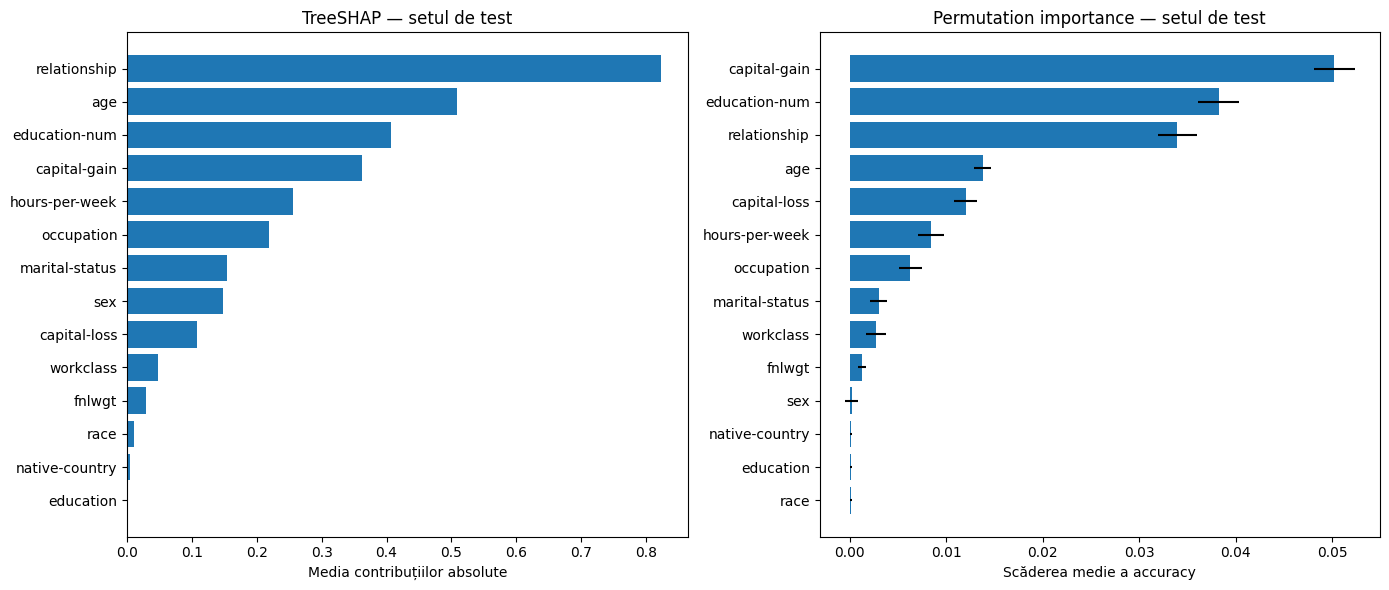

In [ ]:
fig, axe = plt.subplots(1, 2, figsize=(14, 6))

ordine_shap = comparatie.sort_values(
    "Importanță SHAP"
)

axe[0].barh(
    ordine_shap["Caracteristică"],
    ordine_shap["Importanță SHAP"]
)

axe[0].set_title("TreeSHAP — setul de test")
axe[0].set_xlabel("Media contribuțiilor absolute")

ordine_permutare = comparatie.sort_values(
    "Importanță permutare"
)

axe[1].barh(
    ordine_permutare["Caracteristică"],
    ordine_permutare["Importanță permutare"],
    xerr=ordine_permutare["Deviație standard"]
)

axe[1].set_title("Permutation importance — setul de test")
axe[1].set_xlabel("Scăderea medie a accuracy")

plt.tight_layout()
plt.show()

In [ ]:
top_shap = comparatie.sort_values(
    "Importanță SHAP",
    ascending=False
).head(5)["Caracteristică"].tolist()

top_permutare = comparatie.sort_values(
    "Importanță permutare",
    ascending=False
).head(5)["Caracteristică"].tolist()

caracteristici_comune = []

for caracteristica in top_shap:
    if caracteristica in top_permutare:
        caracteristici_comune.append(caracteristica)

print("Top 5 SHAP:")
print(top_shap)

print("\nTop 5 permutation importance:")
print(top_permutare)

print("\nCaracteristici comune celor două topuri:")
print(caracteristici_comune)

print("\nCaracteristici cu cele mai mari diferențe de rang:")

diferente = comparatie.sort_values(
    "Diferență ranguri",
    ascending=False
)

display(
    diferente[
        [
            "Caracteristică",
            "Rang SHAP",
            "Rang permutare",
            "Diferență ranguri"
        ]
    ].head(5)
)

Top 5 SHAP:
['relationship', 'age', 'education-num', 'capital-gain', 'hours-per-week']

Top 5 permutation importance:
['capital-gain', 'education-num', 'relationship', 'age', 'capital-loss']

Caracteristici comune celor două topuri:
['relationship', 'age', 'education-num', 'capital-gain']

Caracteristici cu cele mai mari diferențe de rang:


,Caracteristică,Rang SHAP,Rang permutare,Diferență ranguri
4,capital-loss,9,5,4
3,capital-gain,4,1,3
12,sex,8,11,3
11,race,12,14,2
0,age,2,4,2
